# ResNet18: transfer learning, accuracy and compute

Can pretrained visual features improve on our compact CNN? We compare a frozen feature extractor, late-stage adaptation, regularisation and early spatial downsampling.

The retained standard augmented model reaches validation macro-F1 **0.6281**. Stride 1 reaches **0.6303**, with more missed faults and higher compute cost. The small, single-seed gain needs replication.

This notebook reads recorded results and optional local images. It does not download weights, train a model or evaluate test images. Start with the [CNN baseline](02_baseline_experiments.ipynb); detailed trials remain in the [archive](../archive/README.md).

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault").is_dir():
    raise RuntimeError("Run from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES, CLASS_TO_INDEX
from pv_fault.plots import learning_curves, confusion_matrix, image_examples

SEED = 2112
manifest_path = ROOT / "data/splits/infrared_solar_modules_v1.csv"
manifest_sha = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
manifest_summary = json.loads(manifest_path.with_suffix(".json").read_text())
assert manifest_sha == manifest_summary["manifest_sha256"]
manifest = pd.read_csv(manifest_path, dtype=str)
assert manifest.groupby("group_id")["split"].nunique().eq(1).all()
validation_rows = manifest.loc[manifest["split"].eq("val")]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.")

from torch import nn
from pv_fault.models.resnet import preprocess_thermal, IMAGENET_MEAN, IMAGENET_STD

fresh = json.loads((ROOT / "results/resnet18-reproduction-v1.json").read_text())
generalisation = json.loads((ROOT / "results/resnet18-generalisation-v1.json").read_text())
spatial = json.loads((ROOT / "results/resnet18-spatial-v1.json").read_text())
cnn = json.loads((ROOT / "results/cnn-error-review-v1.json").read_text())
assert all(record["test_evaluated"] is False for record in (fresh, generalisation, spatial))

Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.


## 1. What transfer learning changes

ResNet18 starts with ImageNet features learned from colour photographs. We replace its classifier with 12 outputs, first train only that head, then adapt the final residual block (`layer4`). Earlier weights and all BatchNorm statistics/affine parameters remain fixed during late-stage fitting.

Our images have one channel and little spatial detail. The adapter doubles their size from **40 × 24 to 80 × 48**, repeats brightness into three channels and applies ImageNet normalisation. Resizing adds no new image information. Exactly the same adapter is used for fitting and inference.

In [2]:
mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
example = torch.full((1, 1, 40, 24), .5)
adapted = preprocess_thermal(example, mean, std)
assert tuple(adapted.shape) == (1, 3, 80, 48)
head = nn.Linear(512, len(CLASS_NAMES))
assert sum(p.numel() for p in head.parameters()) == 6156
display(pd.DataFrame({"Channel": ["R copy", "G copy", "B copy"],
    "ImageNet mean": IMAGENET_MEAN, "ImageNet std": IMAGENET_STD,
    "Normalised brightness for input 0.5": adapted[0, :, 0, 0].tolist()}).round(3))
print("The frozen phase trains 6,156 head parameters.")

,Channel,ImageNet mean,ImageNet std,Normalised brightness for input 0.5
0,R copy,0.485,0.229,0.066
1,G copy,0.456,0.224,0.196
2,B copy,0.406,0.225,0.418


The frozen phase trains 6,156 head parameters.


## 2. Follow the progression without losing the controls

1. **Frozen head → layer4:** test whether adapting late features helps thermal images.
2. **Learning rates, duration and scheduling:** improve the training recipe; compare complete configurations.
3. **Generalisation experiments:** separately test mild augmentation, smoothing, class weights and extra stage adaptation. Augmentation gives a small validation gain; more adaptation did not settle the remaining errors.
4. **Spatial variants:** apply one stem change at a time under the same late-stage recipe and common frozen parent.

The table is a development history, not an estimate of independent causal effects across all rows. Matched comparisons and negative trials remain in the [optimisation](../results/resnet18-hour-v1.md) and [generalisation](../results/resnet18-generalisation-v1.md) records.

In [3]:
reference = next(run for run in generalisation["runs"] if run["arm"] == "reference")
progression = [(run["label"], run) for run in fresh["experiments"]]
progression += [("Scheduled layer4", reference)]
progression += [(run["arm"], run) for run in spatial["runs"]]
rows = []
for label, run in progression:
    assert run["plan"]["manifest_sha256"] == manifest_sha
    assert run["verification"]["checkpoint_predictions_verified"]
    assert run["metrics"]["count"] == len(validation_rows)
    metrics = run["metrics"]
    rows.append({"Stage": label, "Macro-F1": metrics["macro_f1"], "Accuracy": metrics["accuracy"],
                 "Balanced accuracy": metrics["balanced_accuracy"],
                 "Missed faults / 1492": metrics["faults_called_normal"],
                 "Normal false alarms / 1496": metrics["normal_called_fault"]})
for run in cnn["models"]:
    metrics = run["metrics"]
    rows.append({"Stage": "SmallCNN: " + run["role"], "Macro-F1": metrics["macro_f1"],
        "Accuracy": metrics["accuracy"], "Balanced accuracy": metrics["balanced_accuracy"],
        "Missed faults / 1492": metrics["faults_called_normal"],
        "Normal false alarms / 1496": metrics["normal_called_fault"]})
display(pd.DataFrame(rows).set_index("Stage").round(4))

,Macro-F1,Accuracy,Balanced accuracy,Missed faults / 1492,Normal false alarms / 1496
Stage,,,,,
Fresh frozen ResNet18,0.4900,0.6921,0.4925,299,156
Fresh layer4 ResNet18,0.5629,0.7319,0.5784,184,162
Scheduled layer4,0.6261,0.7908,0.5966,196,55
standard,0.6281,0.7865,0.6046,198,52
stride1,0.6303,0.7895,0.6040,205,51
no_maxpool,0.6229,0.7825,0.6145,159,91
SmallCNN: Fewer missed faults,0.5964,0.7413,0.6183,82,240
SmallCNN: Highest macro-F1,0.6012,0.7634,0.5934,170,112


## 3. Preserve spatial detail: the final controlled comparison

| Variant | First convolution | Initial max pool | Final layer4 grid |
|---|---|---|---|
| Standard + augmentation | 7 × 7, stride 2 | 3 × 3, stride 2 | `512 × 3 × 2` |
| Stride 1 | Same weights, stride 1 | Unchanged | `512 × 5 × 3` |
| No max pool | Unchanged | Identity | `512 × 5 × 3` |

All three use the same seed, frozen-head parent, augmentation, class weights, optimiser, learning rates and schedule. Only layer4 and the classifier train. Mild augmentation applies horizontal flips and contrast changes to training images only. No validation/test augmentation is used.

Neither spatial change adds learned tensors. **A checkpoint must record and restore the variant:** its weights alone cannot identify the stride or pooling setting. The common parent head was fitted with the standard stem, so this comparison does not exhaust stem-specific head refitting or BatchNorm adaptation.

,Batch size,Head LR,Layer4 LR,Epoch cap,Time cap (min),Augmentation
Variant,,,,,,
standard,64,0.0003,0.00003,10,20.0,True
stride1,64,0.0003,0.00003,10,60.0,True
no_maxpool,64,0.0003,0.00003,10,60.0,True


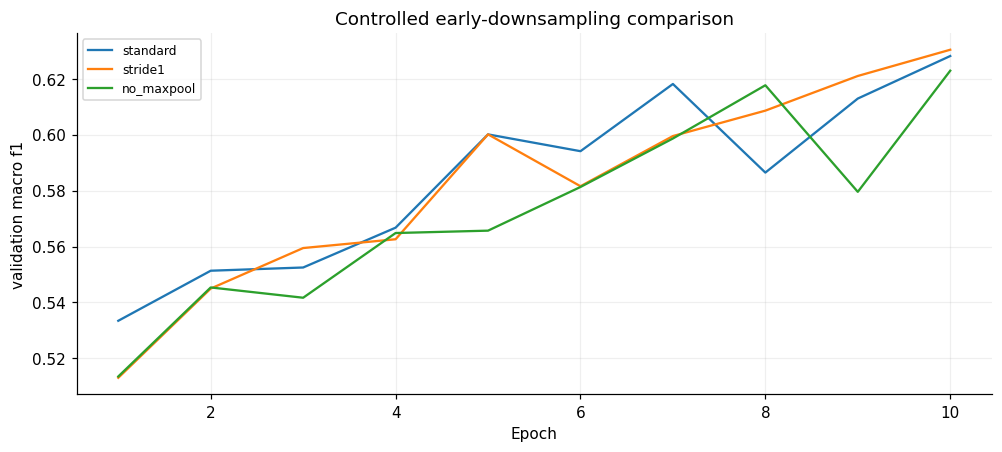

<Axes: title={'center': 'Controlled early-downsampling comparison'}, xlabel='Epoch', ylabel='validation macro f1'>

In [4]:
plan_files = ["experiment-plan-resnet18-generalisation-augmentation.json",
              "experiment-plan-resnet18-spatial-stride1.json",
              "experiment-plan-resnet18-spatial-no_maxpool.json"]
plans = [json.loads((ROOT / "configs" / filename).read_text()) for filename in plan_files]
assert all(plan["manifest_sha256"] == manifest_sha for plan in plans)
display(pd.DataFrame([{"Variant": p.get("spatial_variant", "standard"),
    "Batch size": p["batch_size"], "Head LR": p["head_learning_rate"],
    "Layer4 LR": p["layer4_learning_rate"], "Epoch cap": p["max_epochs"],
    "Time cap (min)": p["max_elapsed_seconds"] / 60,
    "Augmentation": p.get("train_augmentation") is not None} for p in plans]).set_index("Variant"))
learning_curves(spatial["runs"], title="Controlled early-downsampling comparison",
                labels=[run["arm"] for run in spatial["runs"]])

## 4. Inspect class-level errors

The highest-macro-F1 candidate is stride 1. Its confusion matrix uses percentages within each true class, so rare classes remain visible. Compare its recall with the standard model before treating a headline score as an improvement.

The examples are deterministic mistakes from the three weakest classes, selected by image ID. They illustrate failures; they are not a representative sample or evidence that labels are incorrect. Their display is skipped if local images are unavailable.

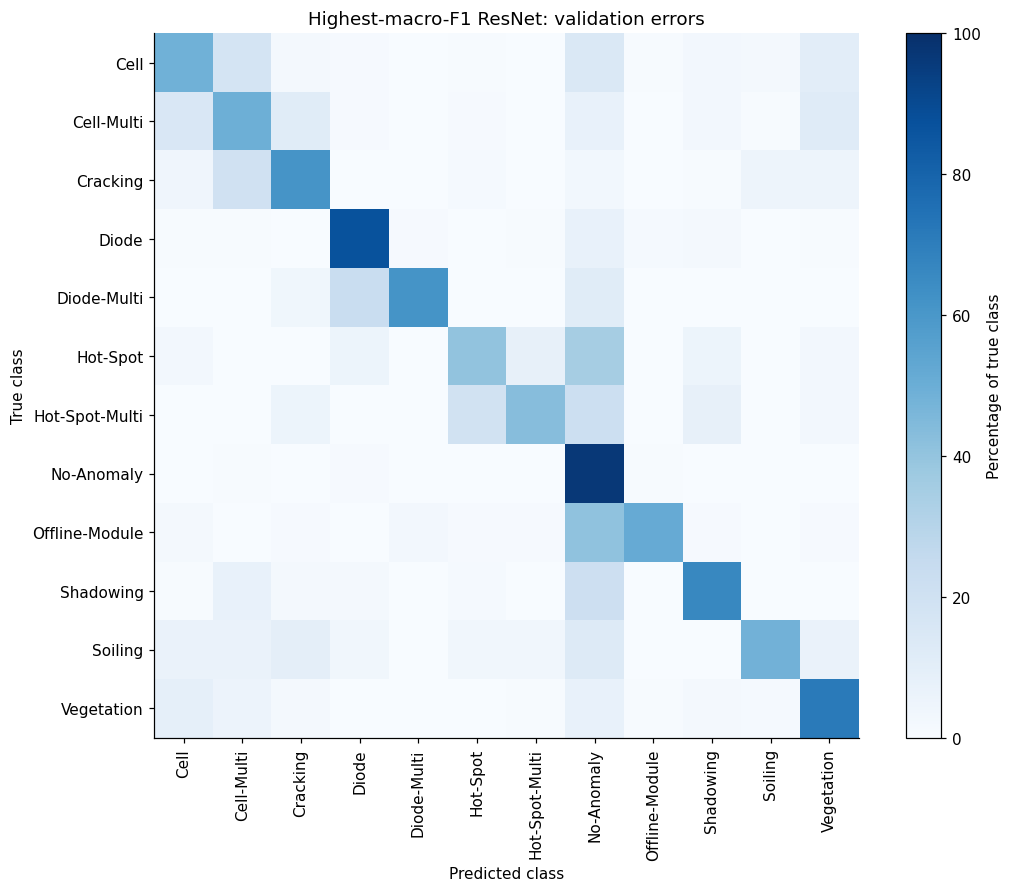

,standard,stride1,Change
Cell,0.561,0.486,-0.075
Cell-Multi,0.425,0.492,0.067
Cracking,0.645,0.610,-0.035
Diode,0.879,0.870,-0.009
Diode-Multi,0.615,0.615,0.000
Hot-Spot,0.514,0.405,-0.108
Hot-Spot-Multi,0.459,0.432,-0.027
No-Anomaly,0.965,0.966,0.001
Offline-Module,0.504,0.512,0.008
Shadowing,0.647,0.660,0.013


,true_label,predicted_label,count,share_of_true_class
0,Offline-Module,No-Anomaly,50,0.406504
1,Cell,Cell-Multi,49,0.175000
2,Cell,No-Anomaly,41,0.146429
3,Shadowing,No-Anomaly,33,0.211538
4,Cell,Vegetation,29,0.103571


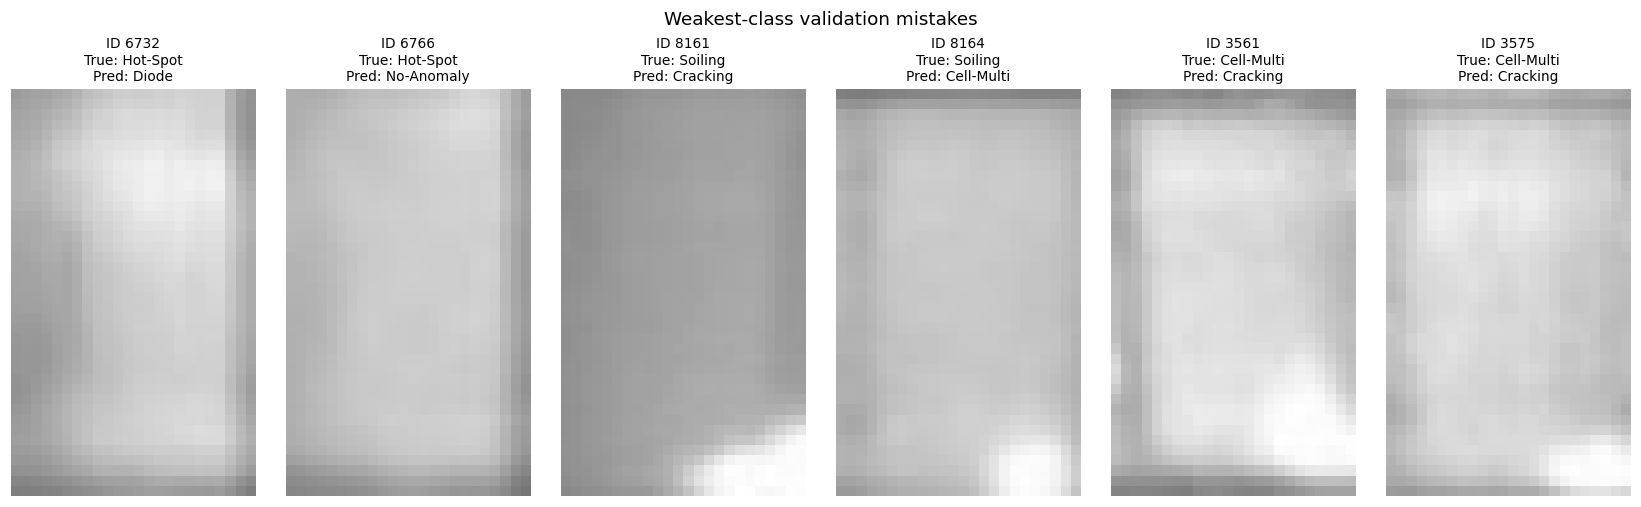

In [5]:
selected = next(run for run in spatial["runs"] if run["run_id"] == spatial["selected_run"])
standard = next(run for run in spatial["runs"] if run["arm"] == "standard")
confusion_matrix(selected["metrics"], "Highest-macro-F1 ResNet: validation errors")
recall = pd.DataFrame({run["arm"]: {label: value["recall"]
    for label, value in run["metrics"]["per_class"].items()} for run in (standard, selected)})
recall["Change"] = recall[selected["arm"]] - recall["standard"]
display(recall.reindex(CLASS_NAMES).round(3))
error_review = spatial["error_review"]
display(pd.DataFrame(error_review["top_confusions"]).head(5))
val_ids = set(validation_rows["image_id"])
assert all(example["image_id"] in val_ids for example in error_review["examples"])
image_examples(error_review["examples"], ROOT / "data/raw", "Weakest-class validation mistakes")

## 5. Account for the compute cost

Parameter count stays constant across ResNet spatial variants; larger activations still increase actual computation. Stride 1 has **11,182,668 total / 8,394,764 trainable parameters**, compared with **47,820** in the selected SmallCNN architecture.

Fit times are historical local CPU measurements, including loading, training, validation and saving; machine load varied. Each workflow reuses a frozen-head parent, whose recorded fitting cost is included separately below. These archived producers ran validation twice per epoch; current code uses one combined pass.

The inference benchmark uses actual checkpoint weights on identical synthetic inputs, four CPU threads, five warmups and twenty timed forwards. It excludes image loading and application overhead. Parameter storage is not peak RAM; energy and FLOPs were not measured.

In [6]:
comparison = pd.DataFrame(spatial["comparison"]).set_index("variant")
display(comparison[["macro_f1", "fit_minutes", "workflow_minutes", "batch_one_ms", "batch64_ms"]].round(4))
benchmark = json.loads((ROOT / "results/resnet18-spatial-v1-inference.json").read_text())
assert benchmark["test_evaluated"] is False
display(pd.DataFrame([{"Model": run["model"], "Parameters": run["total_parameters"],
    "Median batch-one ms": run["batches"][0]["median_batch_ms"],
    "Median batch-64 ms": run["batches"][1]["median_batch_ms"]}
    for run in benchmark["models"]]).set_index("Model").round(3))

,macro_f1,fit_minutes,workflow_minutes,batch_one_ms,batch64_ms
variant,,,,,
standard,0.6281,12.2963,17.2637,2.6102,224.0180
stride1,0.6303,21.2048,26.1721,4.3825,357.4163
no_maxpool,0.6229,23.0022,27.9696,4.2033,326.8312


,Parameters,Median batch-one ms,Median batch-64 ms
Model,,,
standard,11182668,2.610,224.018
stride1,11182668,4.383,357.416
no_maxpool,11182668,4.203,326.831
SmallCNN,47820,0.359,3.754


## 6. What we conclude

- **Keep the standard augmented model as the lower-cost reference.** Its macro-F1 is 0.6281, with 198 missed faults and 52 normal false alarms.
- **Retain stride 1 as a candidate for replication.** Macro-F1 rises by only 0.0022 to 0.6303, while missed faults rise to 205. Its measured batch-one inference is about 1.68× slower.
- **No max pooling is a different trade-off.** It has lower macro-F1 (0.6229), fewer missed faults (159) and more false alarms (91).
- **ResNet improves the selected validation macro-F1 over SmallCNN at substantial compute cost.** Model choice also depends on missed faults, false alarms and available hardware.

All selection uses the same development validation set and mainly one seed. Repeated selection can overestimate gains; rare-class estimates have small denominators. The duplicate-aware split has no verified site/panel identities and cannot establish unseen-site performance. Test inference was reserved during development; the frozen final evaluation is reported separately below. None of these models certifies panel safety or reuse suitability.

## 7. Reproduce deliberately

Prepare the dataset using [data setup](../data/README.md), then verify the pinned ImageNet weights and run a two-batch diagnostic:

```bash
PYTHONPATH=src python scripts/fetch_resnet18_weights.py
PYTHONPATH=src python scripts/fetch_resnet18_weights.py --verify-only
PYTHONPATH=src python scripts/train_resnet18.py --plan configs/experiment-plan-resnet18-frozen-repro.json
PYTHONPATH=src python scripts/finetune_resnet18.py --plan configs/experiment-plan-resnet18-generalisation-augmentation.json
```

The spatial alternatives are [stride 1](../configs/experiment-plan-resnet18-spatial-stride1.json) and [no max pooling](../configs/experiment-plan-resnet18-spatial-no_maxpool.json). Use the same fine-tuning command with the corresponding plan.

Diagnostics do not save full fits. To train fully, use a copied plan with a new run ID, verify the frozen dataset, and add `--full`. Child plans require the exact parent checkpoint checksum. A freshly fitted parent requires a new child plan with its actual fingerprint; preserve the recorded plans and results.

See the [archive index](../archive/README.md) for older learning-rate/CV commands and reports. The old CV-selected recipe still requires its original CV summary, which is not present in this local checkout. All historical evidence remains under `results/`.

## 8. Final reserved-test evaluation

Before test inference, we committed the [final protocol](../configs/final-evaluation-v1.json): the standard augmented ResNet, the higher-macro-F1 SmallCNN reference and the training-majority baseline. We chose standard ResNet for its lower compute cost and validation error trade-off, not by looking at test outcomes.

Each learned model's screening threshold was fixed on validation at the highest cutoff meeting 90% anomaly recall. Validation false-alarm rates also met the 20% target. We then ran the frozen choices once on all **2,988 test images**, with no further training or threshold changes. Multiclass argmax and binary screening remain separate decisions.

ResNet's **test macro-F1 is 0.6232**, versus **0.5957** for the predefined CNN baseline. Its screening recall is **89.48%**, with **4.75% false alarms**: the 90% recall point target was narrowly missed. The CNN also missed that target. We report the shortfall without tuning against the test set. Higher observed multiclass F1 does not establish a statistically significant or unseen-site advantage.

The intervals below resample recorded related-image groups 1,000 times at a fixed seed. Missing real site identities still limit independence. These results support a qualified, offline screening comparison and cannot certify panel safety or reuse.

,Accuracy,Macro-F1,Argmax missed faults,Argmax false alarms,Screening recall,Screening false-alarm rate
Model,,,,,,
Majority baseline,0.5007,0.0556,1492,0,0.0000,0.0000
SmallCNN,0.7651,0.5957,193,85,0.8968,0.0762
ResNet18,0.7885,0.6232,210,43,0.8948,0.0475


,support,precision,recall,f1
Cell,280.0,0.604,0.593,0.598
Cell-Multi,193.0,0.493,0.373,0.425
Cracking,141.0,0.721,0.624,0.669
Diode,223.0,0.941,0.924,0.932
Diode-Multi,26.0,0.850,0.654,0.739
Hot-Spot,37.0,0.349,0.405,0.375
Hot-Spot-Multi,37.0,0.533,0.649,0.585
No-Anomaly,1496.0,0.874,0.971,0.920
Offline-Module,123.0,0.836,0.496,0.622
Shadowing,156.0,0.713,0.590,0.646


,lower,upper,valid_resamples
accuracy,0.7724,0.8035,1000.0
macro_f1,0.5939,0.6515,1000.0
balanced_accuracy,0.5697,0.6336,1000.0
screening_recall,0.8785,0.9084,1000.0
screening_false_alarm_rate,0.0362,0.0591,1000.0


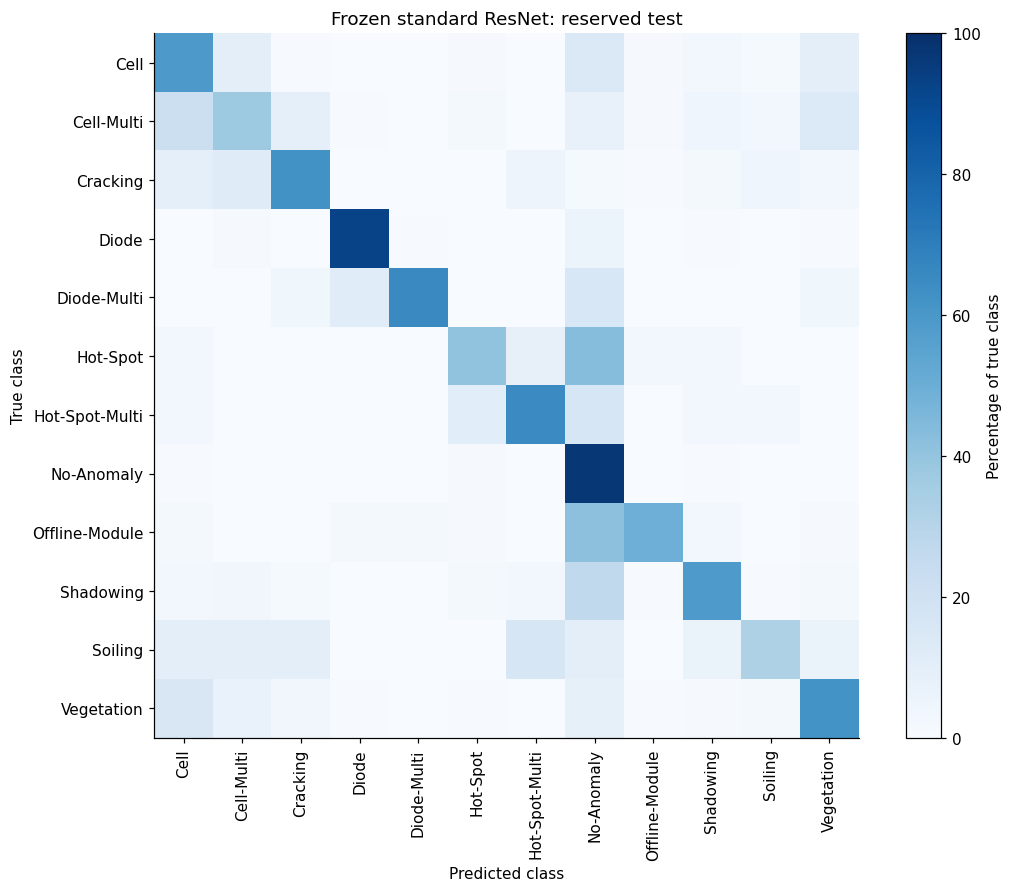

Protocol and evaluation code were frozen in commit: 3ef4040e232ff8e5945c5989153f48401a8a5949
Thresholds remain unchanged. Full records: results/final-evaluation-v1.json


In [7]:
final_path = ROOT / "results/final-evaluation-v1.json"
final = json.loads(final_path.read_text())
protocol_path = ROOT / "configs/final-evaluation-v1.json"
assert final["split"] == "test" and final["test_evaluated"] is True
assert final["protocol_sha256"] == hashlib.sha256(protocol_path.read_bytes()).hexdigest()
final_rows = []
for name, record in final["models"].items():
    metrics, screening = record["multiclass"], record["screening"]
    final_rows.append({"Model": name, "Accuracy": metrics["accuracy"], "Macro-F1": metrics["macro_f1"],
        "Argmax missed faults": metrics["faults_called_normal"],
        "Argmax false alarms": metrics["normal_called_fault"],
        "Screening recall": screening["recall"], "Screening false-alarm rate": screening["false_alarm_rate"]})
display(pd.DataFrame(final_rows).set_index("Model").round(4))
resnet_test = final["models"]["ResNet18"]
display(pd.DataFrame(resnet_test["multiclass"]["per_class"]).T.round(3))
display(pd.DataFrame(resnet_test["intervals"]["bounds"]).T.round(4))
confusion_matrix(resnet_test["multiclass"], "Frozen standard ResNet: reserved test")
print("Protocol and evaluation code were frozen in commit:", final["evaluation_commit"])
print("Thresholds remain unchanged. Full records: results/final-evaluation-v1.json")